In [120]:

import numpy as np

import salvus.namespace as sn

import salvus.mesh
import salvus.mesh.layered_meshing as lm
from my_code.utilities import *
from pathlib import Path
from material_ela_constants.Elastic_Material import * 
from salvus.toolbox.helpers.wavefield_output import (
    WavefieldOutput,
    wavefield_output_to_xarray,
)

# Directories in WSL
PROJECT_DIR = '/home/oliver/workspace/Salvus/elastic_model/anisotropic/Project'
IMAGE_DIR = '/home/oliver/workspace/Salvus/elastic_model/anisotropic/image'
DATA_DIR = '/home/oliver/workspace/Salvus/elastic_model/anisotropic/data'


# Directories in Windows
PROJECT_DIR_WIN = '/mnt/f/Salvus_project/elastic_model/anisotropic/Project'
DATA_DIR_WIN = '/mnt/f/Salvus_project/elastic_model/anisotropic/data'
IMAGE_DIR_WIN = '/mnt/f/Salvus_project/elastic_model/anisotropic/image'


# create dir if it does not exist
Path(IMAGE_DIR).mkdir(parents=True, exist_ok=True)
Path(DATA_DIR).mkdir(parents=True, exist_ok=True)
Path(IMAGE_DIR_WIN).mkdir(parents=True, exist_ok=True)
Path(DATA_DIR_WIN).mkdir(parents=True, exist_ok=True)



# salvus site 
SITE_NAME = "oliver_wsl"
RANKS = 8


# center frequency 
CENTRAL_FREQUENCY = 1e6 
f_c = CENTRAL_FREQUENCY
sampling_rate_in_hertz = CENTRAL_FREQUENCY *200
time_step_in_seconds = 1/sampling_rate_in_hertz



n_rxs = 1
n_txs = 1


x0, x1 = 0.0, 0.01
y0, y1 = 0.0, 0.01



# material properties
matl = Austenite()
VP_0deg = np.sqrt(matl.C33 / matl.RHO)
VP_90deg = np.sqrt(matl.C11 / matl.RHO)

# ---- Mesh resolution ----------------------------------------------------
elements_per_wavelength = 3
model_order             = 4
reference_velocity      = VP_0deg
number_of_wavelengths   = 2
reference_frequency     = CENTRAL_FREQUENCY * 2
free_surfaces           = False


smoothing = 0

# project name (folder's name)
PROJECT_NAME = fr"tomography_solid_orientation_singlelayer"



domain = sn.domain.dim2.BoxDomain(x0=x0, x1=x1, y0=y0, y1=y1)

p = sn.Project.from_domain(
    path=Path(PROJECT_DIR_WIN, PROJECT_NAME), domain=domain, load_if_exists=True
)




Accordion(children=(HTML(value='\n                <head>\n                <style>\n                td {\n     …

[2026-10-26 16:11:49,105] INFO: Loading project from /mnt/f/Salvus_project/elastic_model/anisotropic/Project/tomography_solid_orientation_singlelayer.


In [121]:
def forward_simulation(simulation_name, events,
                       fields=None, sampling_interval_in_time_steps=10):
    _n_events = 1 if isinstance(events, str) else len(events)
    print(f"  [forward_simulation] launching '{simulation_name}' "
          f"for {_n_events} event(s), volume_output={'yes' if fields else 'no'} ...")
    if fields:
        p.simulations.launch(
            ranks_per_job=RANKS,
            site_name=SITE_NAME,
            events=events,
            simulation_configuration=simulation_name,
            extra_output_configuration={
                "volume_data": {
                    "sampling_interval_in_time_steps": sampling_interval_in_time_steps,
                    "fields": fields,
                },
            },
            delete_conflicting_previous_results=True,
        )
    else:
        p.simulations.launch(
            ranks_per_job=RANKS,
            site_name=SITE_NAME,
            events=events,
            simulation_configuration=simulation_name,
            delete_conflicting_previous_results=True,
        )

    p.simulations.query(block=True, verbosity=-1)
    print(f"  [forward_simulation] '{simulation_name}' finished.")


def extract_data(simulation, events, receiver_field='displacement', field=None):
    ed = p.waveforms.get(data_name=simulation, events=events)[0]
    data = ed.get_waveform_data_xarray(receiver_field=receiver_field)
    wavefield = None
    if field:
        wavefield = wavefield_output_to_xarray(
            ed.get_wavefield_output(output_type='volume', field=field),
            p.simulations.get_mesh(simulation).points,
        ).T
    return data, wavefield


In [122]:
# extract the waveforms and wavefields for all events in the simulation
SIMULATION_NAME = "forward_simulation"
event_ls = p.events.list()          # all events registered in the project, e.g. ['src_1']

# receiver_data[event] : xarray (trace, time); traces = (receiver_id, component X/Y)
# wavefields[event]    : xarray (point, c, t); volume displacement at mesh points
receiver_data, wavefields = {}, {}
for event_name in event_ls:
    receiver_data[event_name], wavefields[event_name] = extract_data(
        SIMULATION_NAME, event_name, receiver_field='displacement', field='displacement'
    )
    print(f"{event_name}: receiver data {dict(receiver_data[event_name].sizes)}, "
          f"wavefield {dict(wavefields[event_name].sizes)}")

# time axis of the receiver data [s]
t = receiver_data[event_ls[0]].time.values

Finding enclosing elements (pass 1 of auto):   0%|          | 0/206989 [00:00<?, ?it/s]

Extracting wavefield to regular grid:   0%|          | 0/9 [00:00<?, ?it/s]

src_1: receiver data {'trace': 2, 'time': 1376}, wavefield {'point': 206989, 'c': 2, 't': 139}


In [123]:
receiver_data['src_1']

<xarray.DataArray 'displacement' (trace: 2, time: 1376)> Size: 11kB
array([[ 0.0000000e+00,  0.0000000e+00,  0.0000000e+00, ...,
         1.3282440e-05,  1.2223563e-05,  1.1174795e-05],
       [ 0.0000000e+00,  0.0000000e+00,  0.0000000e+00, ...,
        -1.0237389e-04, -1.0245507e-04, -1.0254892e-04]],
      shape=(2, 1376), dtype=float32)
Coordinates:
  * trace        (trace) object 16B MultiIndex
  * receiver_id  (trace) <U6 48B 'XX.R1.' 'XX.R1.'
  * component    (trace) <U1 8B 'X' 'Y'
  * time         (time) float64 11kB -1.5e-06 -1.496e-06 ... 3.996e-06 4e-06
Attributes:
    start_time_in_seconds:               -1.5e-06
    sampling_rate_in_hertz:              249999999.99999997
    start_time_in_seconds_utc_datetime:  1969-12-31T23:59:59.999998Z
    end_time_in_seconds_utc_datetime:    1970-01-01T00:00:00.000004Z
    reference_time_utc:                  1970-01-01T00:00:00.000000Z
    reference_time_in_seconds:           0.0
    npts:                                1376
    location:                            [[0.005 0.001]]

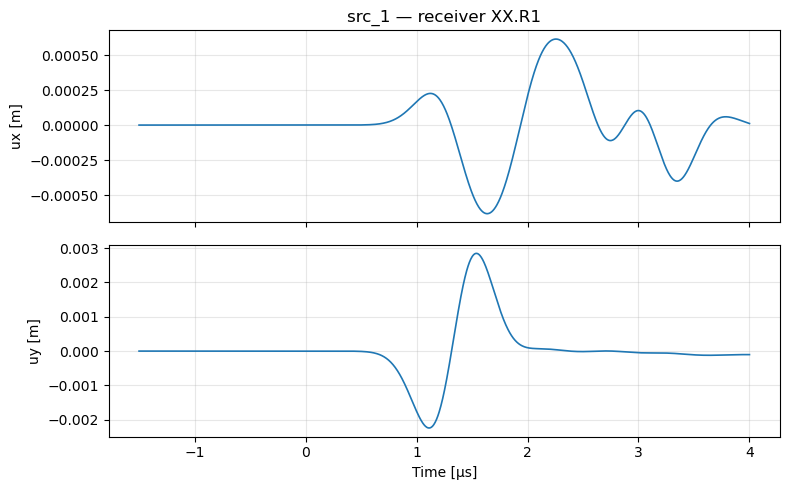

In [124]:
# plot X and Y displacement at each receiver in the time domain
for event_name in event_ls:
    data = receiver_data[event_name]
    for rec_id in np.unique(data.receiver_id.values):
        rec = data.sel(receiver_id=rec_id)

        fig, axes = plt.subplots(2, 1, figsize=(8, 5), dpi=100, sharex=True)
        for ax, comp in zip(axes, ['X', 'Y']):
            ax.plot(rec.time.values * 1e6, rec.sel(component=comp).values.squeeze(), lw=1.2)
            ax.set_ylabel(f'u{comp.lower()} [m]')
            ax.grid(alpha=0.3)
        axes[-1].set_xlabel('Time [µs]')
        axes[0].set_title(f'{event_name} — receiver {rec_id.strip(".")}')
        plt.tight_layout()
        plt.show()

